# Minería de Datos · Sesión 4: Transformación, Escalamiento y Reducción de Datos (PCA)
## Metodología CRISP-DM · PEA UNIMINUTO
### Proyecto AUTOGEST: Siniestralidad Vial y Movilidad

Este cuaderno desarrolla las técnicas avanzadas de preparación de datos:
1. Demostración del impacto del sesgo de escala en distancias euclídeas ("El Gancho").
2. Comparación de escaladores (`MinMaxScaler`, `StandardScaler`, `RobustScaler`).
3. Codificación de variables categóricas mediante One-Hot Encoding.
4. Discretización de variables continuas (`KBinsDiscretizer`).
5. Reducción de dimensionalidad mediante Análisis de Componentes Principales (PCA).


## 1. Importación de librerías y clase modular


In [1]:
import sys
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sys.path.append("..")

from src.transformacion import Transformacion


## 2. Carga del Dataset Integrado y Diagnóstico de Escala


In [2]:
trans = Transformacion("../dataset/dataset_integrado.csv")
df = trans.cargar()
trans.diagnosticar()


DIAGNÓSTICO DE ESCALA Y TRANSFORMACIÓN · AUTOGEST
Dimensiones: 507 filas × 18 columnas

Variables continuas predictoras: ['AÑO', 'MES', 'VOLUMEN_TRAFICO', 'VEHICULOS_EVASORES', 'VEHICULOS_EXENTOS', 'SERVICIOS_TALLER', 'COSTO_TOTAL_TALLER', 'MILLAJE_PROMEDIO']
Variables categóricas: ['TIPO_VEHICULO']
Variable objetivo: ACCIDENTES_REGISTRADOS

Estadísticos descriptivos básicos:
           AÑO     MES  ...  COSTO_TOTAL_TALLER  MILLAJE_PROMEDIO
count   507.00  507.00  ...              507.00            507.00
mean   2019.99    6.40  ...          1476214.65          73356.10
std       3.49    3.46  ...          1717313.56          77451.78
min    2014.00    1.00  ...                0.00              0.00
25%    2017.00    3.00  ...                0.00              0.00
50%    2020.00    6.00  ...                0.00              0.00
75%    2023.00    9.00  ...          2159990.52         154889.66
max    2026.00   12.00  ...          4367279.09         157924.86

[8 rows x 8 columns]



## 3. El Gancho: La columna que secuestró la distancia
Evaluación del efecto de magnitudes dispares (ej. volumen de tráfico en millones vs años en unidades) sobre el cálculo de proximidad euclídea.


In [3]:
resumen_dist = trans.demostrar_impacto_distancia(idx1=0, idx2=1)
print("Demostración de Sesgo en Distancia Euclídea:")
for k, v in resumen_dist.items():
    print(f"  • {k}: {v}")


Demostración de Sesgo en Distancia Euclídea:
  • registro_a: 0
  • registro_b: 1
  • distancia_sin_escalar: 10845277.43
  • distancia_escalada_minmax: 0.706
  • conclusion: Sin escalamiento, la variable con mayor varianza domina el 99%+ de la distancia euclídea.



## 4. Comparación de Métodos de Escalamiento


In [4]:
df_minmax, df_std, df_rob = trans.comparar_escaladores()
print("Estadísticas con MinMaxScaler:")
display(df_minmax.describe().round(3))
print("Estadísticas con StandardScaler:")
display(df_std.describe().round(3))
print("Estadísticas con RobustScaler:")
display(df_rob.describe().round(3))


Estadísticas con MinMaxScaler:
Estadísticas con StandardScaler:
Estadísticas con RobustScaler:



,AÑO_minmax,MES_minmax,VOLUMEN_TRAFICO_minmax,VEHICULOS_EVASORES_minmax,VEHICULOS_EXENTOS_minmax,SERVICIOS_TALLER_minmax,COSTO_TOTAL_TALLER_minmax,MILLAJE_PROMEDIO_minmax
count,507.000,507.000,507.000,507.000,507.000,507.000,507.000,507.000
mean,0.499,0.491,0.289,0.004,0.223,0.343,0.338,0.465
std,0.291,0.315,0.264,0.050,0.277,0.398,0.393,0.490
min,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
25%,0.250,0.182,0.140,0.000,0.042,0.000,0.000,0.000
50%,0.500,0.455,0.160,0.000,0.061,0.000,0.000,0.000
75%,0.750,0.727,0.537,0.000,0.587,0.499,0.495,0.981
max,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000


,AÑO_std,MES_std,VOLUMEN_TRAFICO_std,VEHICULOS_EVASORES_std,VEHICULOS_EXENTOS_std,SERVICIOS_TALLER_std,COSTO_TOTAL_TALLER_std,MILLAJE_PROMEDIO_std
count,507.000,507.000,507.000,507.000,507.000,507.000,507.000,507.000
mean,-0.000,-0.000,-0.000,0.000,-0.000,-0.000,-0.000,0.000
std,1.001,1.001,1.001,1.001,1.001,1.001,1.001,1.001
min,-1.719,-1.559,-1.099,-0.085,-0.804,-0.861,-0.860,-0.948
25%,-0.858,-0.981,-0.569,-0.085,-0.653,-0.861,-0.860,-0.948
50%,0.003,-0.115,-0.493,-0.084,-0.584,-0.861,-0.860,-0.948
75%,0.864,0.752,0.941,-0.083,1.314,0.392,0.399,1.054
max,1.725,1.619,2.698,19.880,2.807,1.652,1.685,1.093


,AÑO_rob,MES_rob,VOLUMEN_TRAFICO_rob,VEHICULOS_EVASORES_rob,VEHICULOS_EXENTOS_rob,SERVICIOS_TALLER_rob,COSTO_TOTAL_TALLER_rob,MILLAJE_PROMEDIO_rob
count,507.000,507.000,507.000,507.000,507.000,507.000,507.000,507.000
mean,-0.002,0.066,0.326,53.668,0.297,0.687,0.683,0.474
std,0.581,0.577,0.663,636.828,0.509,0.799,0.795,0.500
min,-1.000,-0.833,-0.402,-0.093,-0.112,0.000,0.000,0.000
25%,-0.500,-0.500,-0.051,-0.093,-0.035,0.000,0.000,0.000
50%,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
75%,0.500,0.500,0.949,0.907,0.965,1.000,1.000,1.000
max,1.000,1.000,2.112,12701.163,1.724,2.006,2.022,1.020


## 5. Codificación de Variables Categóricas (One-Hot Encoding)


In [5]:
df_dummies = trans.codificar_onehot()
print("Variables dummificadas:")
display(df_dummies.head())


Variables dummificadas:



,TIPO_VEHICULO_CARGA_PESADO,TIPO_VEHICULO_LIVIANO,TIPO_VEHICULO_OTRO,TIPO_VEHICULO_TRANSPORTE_PASAJEROS
0,1,0,0,0
1,0,1,0,0
2,0,0,0,1
3,1,0,0,0
4,0,1,0,0


## 6. Discretización de Variables Continuas (KBinsDiscretizer)


In [6]:
serie_bin, bordes = trans.discretizar(columna="AÑO", n_bins=4, estrategia="uniform")
print("Bordes de intervalos temporales:", bordes)
print("Distribución de observaciones por bin:")
display(serie_bin.value_counts().sort_index())


Bordes de intervalos temporales: [2014. 2017. 2020. 2023. 2026.]
Distribución de observaciones por bin:



,count
AÑO_BIN,
0.0,108
1.0,108
2.0,144
3.0,147


## 7. Reducción de Dimensionalidad con PCA
Aplicación de PCA sobre las variables cuantitativas continuas estandarizadas.


In [7]:
df_pca, resumen_pca = trans.aplicar_pca(n_componentes=5)
print(f"Número de componentes evaluados: {resumen_pca['n_componentes']}")
print(f"Varianza explicada individual : {resumen_pca['varianza_individual']}")
print(f"Varianza explicada acumulada  : {resumen_pca['varianza_acumulada']}")
print(f"Porcentaje total explicado    : {resumen_pca['pct_total_explicado']:.2f}%")


Número de componentes evaluados: 5
Varianza explicada individual : [0.4046, 0.2497, 0.1287, 0.1221, 0.078]
Varianza explicada acumulada  : [0.4046, 0.6543, 0.783, 0.9051, 0.9831]
Porcentaje total explicado    : 98.31%



### 7.1 Visualización: Scree Plot (Varianza Explicada Acumulada)


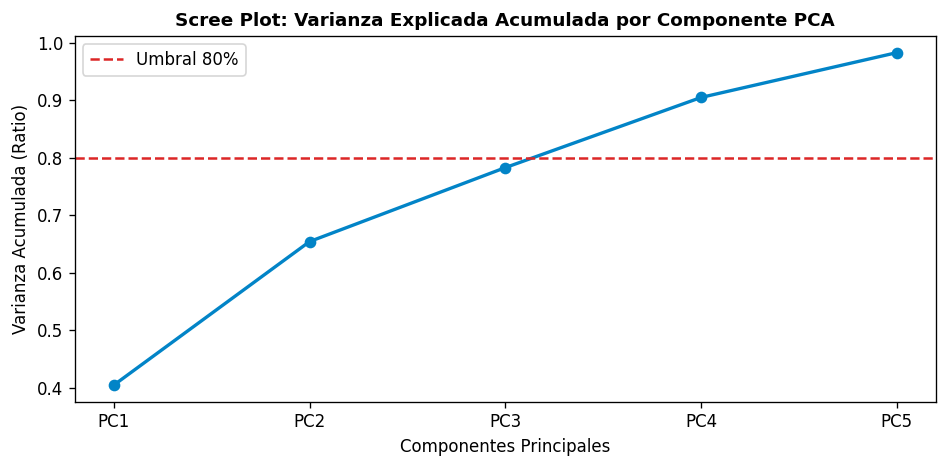

In [8]:
plt.figure(figsize=(8, 4), dpi=120)
comp_labels = [f"PC{i+1}" for i in range(resumen_pca['n_componentes'])]
plt.plot(comp_labels, resumen_pca['varianza_acumulada'], marker="o", color="#0284c7", linewidth=2)
plt.axhline(0.80, color="#dc2626", linestyle="--", label="Umbral 80%")
plt.title("Scree Plot: Varianza Explicada Acumulada por Componente PCA", fontsize=11, fontweight="bold")
plt.xlabel("Componentes Principales")
plt.ylabel("Varianza Acumulada (Ratio)")
plt.legend()
plt.tight_layout()
plt.show()


### 7.2 Proyección 2D: Primeros dos componentes (PC1 vs PC2)


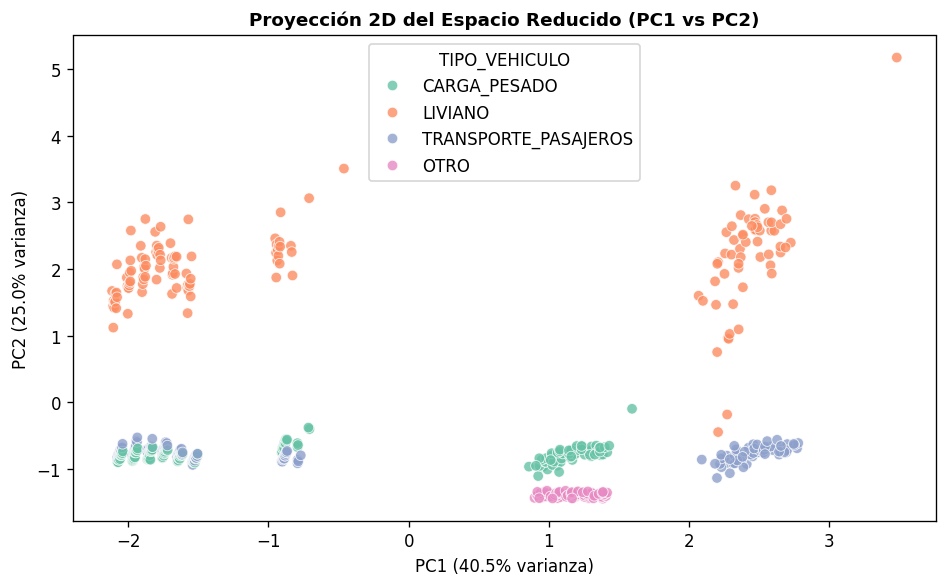

In [9]:
plt.figure(figsize=(8, 5), dpi=120)
sns.scatterplot(
    data=df_pca, x="PC1", y="PC2",
    hue=df["TIPO_VEHICULO"] if "TIPO_VEHICULO" in df.columns else None,
    palette="Set2", alpha=0.8, s=40
)
plt.title("Proyección 2D del Espacio Reducido (PC1 vs PC2)", fontsize=11, fontweight="bold")
plt.xlabel(f"PC1 ({resumen_pca['varianza_individual'][0]*100:.1f}% varianza)")
plt.ylabel(f"PC2 ({resumen_pca['varianza_individual'][1]*100:.1f}% varianza)")
plt.tight_layout()
plt.show()


## 8. Exportación del Dataset Reducido


In [10]:
df_reducido, _ = trans.generar_dataset_reducido(n_componentes=5)
trans.guardar_reducido("../dataset/dataset_reducido.csv")
print("Muestra del dataset reducido exportado:")
display(df_reducido.head())


[OK] Dataset reducido guardado exitosamente en: ..\dataset\dataset_reducido.csv
Dimensiones finales: 507 filas × 9 columnas
Muestra del dataset reducido exportado:



,AÑO,MES,TIPO_VEHICULO,PC1,PC2,PC3,PC4,PC5,ACCIDENTES_REGISTRADOS
0,2014,1,CARGA_PESADO,-2.075815,-0.896523,-0.945910,-0.926094,-1.265347,468.0
1,2014,1,LIVIANO,-2.114946,1.670303,-0.812639,-1.257080,-1.131947,2085.0
2,2014,1,TRANSPORTE_PASAJEROS,-2.077459,-0.827552,-0.939741,-0.936736,-1.270003,459.0
3,2014,2,CARGA_PESADO,-2.072059,-0.903029,-0.725381,-0.744488,-1.219800,580.0
4,2014,2,LIVIANO,-2.106175,1.119823,-0.606486,-1.014258,-1.161205,1829.0
